# 09 — Full active loop on Goldstein (dry run of exp0)

The exp0 settings from config.py: goldstein_graded and goldstein_flip, methods category_wise /
dc / gower / hs_dim, seeds 1-3, 100 samples, 2 initial samples per category, no plateau stop.
Then F1 against samples for hs_dim, and the evaluation store: does a rerun replay for free and
an extended budget evaluate only the new points?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mvlse import run_lse, score_level_set
from mvlse.benchmark import compare_active, test_grid
from mvlse.problems import get_problem

sys.path.insert(0, str(Path.cwd().parent))
import config

P = config.EXPERIMENTS["exp0_verify"]
print(P)

{'problems': ['goldstein_graded', 'goldstein_flip'], 'methods': ['category_wise', 'dc', 'gower', 'hs_dim'], 'seeds': [1, 2, 3], 'max_evaluations': 100, 'n_init_per_category': 2}


In [2]:
tables = []
for name in P["problems"]:
    print(name)
    frame = compare_active(get_problem(name), methods=P["methods"], seeds=P["seeds"],
                           max_evaluations=P["max_evaluations"], n_init_per_category=P["n_init_per_category"],
                           flip_tolerance=config.LSE["flip_tolerance"])
    tables.append(frame.assign(problem=name))
pd.concat(tables)

goldstein_graded


category_wise  F1=0.760 +- 0.017  acc=73.2%  n=100  [25.9s]


dc             F1=0.998 +- 0.000  acc=99.8%  n=100  [49.8s]


gower          F1=0.994 +- 0.001  acc=99.4%  n=100  [72.0s]


hs_dim         F1=0.999 +- 0.000  acc=99.9%  n=96   [243.5s]


goldstein_flip


category_wise  F1=0.797 +- 0.013  acc=76.5%  n=100  [25.1s]


dc             F1=0.998 +- 0.000  acc=99.7%  n=100  [45.1s]


gower          F1=0.993 +- 0.002  acc=99.2%  n=100  [59.4s]


hs_dim         F1=0.999 +- 0.000  acc=99.9%  n=95   [238.0s]


,problem,method,n_train,n_hyper,f1,f1_std,accuracy,rmse,seconds
0,goldstein_graded,category_wise,100,54,0.759638,0.016533,0.732146,1.720427,25.856995
1,goldstein_graded,dc,100,5,0.998269,0.000073,0.998096,0.062621,49.804787
2,goldstein_graded,gower,100,5,0.994271,0.000628,0.993701,0.096319,72.045285
3,goldstein_graded,hs_dim,96,11,0.999313,0.000165,0.999244,0.020830,243.523967
0,goldstein_flip,category_wise,100,54,0.796731,0.012571,0.764788,0.777891,25.142729
1,goldstein_flip,dc,100,5,0.997657,0.000036,0.997424,0.041408,45.105634
2,goldstein_flip,gower,100,5,0.993095,0.001546,0.992413,0.091295,59.408848
3,goldstein_flip,hs_dim,95,11,0.999313,0.000225,0.999244,0.010909,237.993115


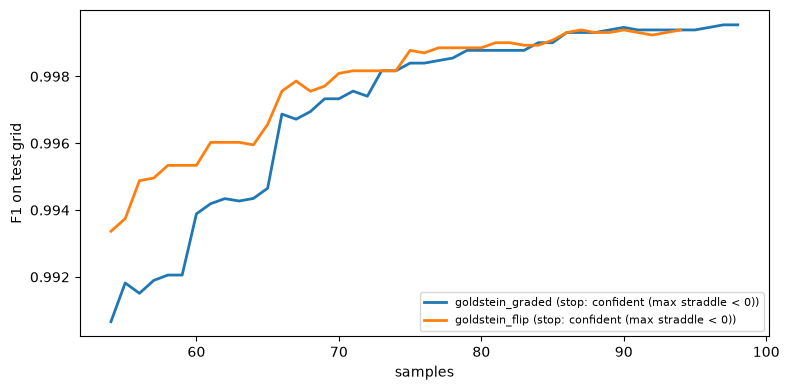

In [3]:
# F1 on the test grid after every round, hs_dim seed 1.
fig, ax = plt.subplots(figsize=(8, 4))
for name in P["problems"]:
    prob = get_problem(name)
    grid = test_grid(prob)
    truth = prob.truth(grid)
    res = run_lse(prob.space, prob, threshold=prob.threshold, method="hs_dim", seed=1,
                  max_evaluations=P["max_evaluations"], n_init_per_category=P["n_init_per_category"],
                  flip_tolerance=-1.0, monitor=grid, keep_snapshots=True, verbose=False)
    f1 = [score_level_set(m, truth, prob.threshold).f1 for m, _ in res.snapshots]
    ax.plot([r.n_evaluations for r in res.rounds], f1, lw=2, label=f"{name} (stop: {res.stop_reason})")
ax.set_xlabel("samples"); ax.set_ylabel("F1 on test grid"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
# Evaluation store: rerun and extension.
prob = get_problem("goldstein_graded")
store = Path("results/store_check.jsonl")
store.unlink(missing_ok=True)
calls = {"n": 0}

def counted(points):
    calls["n"] += len(points)
    return prob(points)

runs = {}
for label, budget in (("first run", 70), ("same run again", 70), ("budget raised to 80", 80)):
    calls["n"] = 0
    runs[label] = run_lse(prob.space, counted, threshold=prob.threshold, method="hs_dim", seed=1,
                          max_evaluations=budget, n_init_per_category=2, flip_tolerance=-1.0,
                          store=store, verbose=False)
    print(f"{label:22s} samples={runs[label].n_evaluations:3d}  blackbox evaluations={calls['n']:3d}")
a, b, c = runs.values()
print("rerun identical samples and responses:", np.array_equal(a.w, b.w) and np.array_equal(a.y, b.y))
print("extension starts with the first run's samples:", np.array_equal(c.w[:len(a.w)], a.w))

first run              samples= 70  blackbox evaluations= 70


same run again         samples= 70  blackbox evaluations=  0


budget raised to 80    samples= 80  blackbox evaluations= 10
rerun identical samples and responses: True
extension starts with the first run's samples: False
